# 07 · How pizzetti computes a light curve

**Level:** advanced · **Prerequisites:** [01](01_first_light_curve.ipynb), [04](04_observing_realities.ipynb) · **Run time:** ~30 s

**Covers:** `occult`, `series_cut` and the cut z_c, the regimes of a transit, every `limb` option (`fast`, `interpolate`, `trapezoid`, `contact`, `quadrature`, `proven`) with its accuracy and cost

`TransitModel` turns times into separations z and calls `occult(z, rp, u, law)`. Here we call it directly and look inside: which method handles which part of the transit, and what each costs.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pizzetti
from pizzetti import occult, series_cut

def best(f, repeat=7):
    f(); ts = []
    for _ in range(repeat):
        s = time.perf_counter(); f(); ts.append(time.perf_counter() - s)
    return min(ts)

## 1. The low-level function

`occult(z, rp, u, limb_dark)` returns the relative flux for projected centre separations `z` (stellar radii).
It accepts the same law names and coefficients as `TransitParams`.

In [2]:
rp, law, u = 0.1, "power2", [0.7, 0.6]
z = np.linspace(0, 1.2, 4001)
f = occult(z, rp, u, law)
z_c = series_cut(rp, law, u)
print(f"z_c = {z_c:.4f}  (second contact at 1 - rp = {1 - rp}, first contact at 1 + rp = {1 + rp})")

z_c = 0.8180  (second contact at 1 - rp = 0.9, first contact at 1 + rp = 1.1)


## 2. Four regimes

| separation | what pizzetti does |
|---|---|
| z ≤ z_c | **interior series**: `sqrt(1 − z²)`, or `(1 − z²)^(α/2)`, times a degree-11 polynomial in `1/(1 − z²)`; error proven below `series_tol` |
| z_c < z < 1 − rp | planet still inside the disk but close to the limb, where the series converges too slowly |
| 1 − rp < z < 1 + rp | planet crossing the limb (ingress/egress) |
| z ≥ 1 + rp | no overlap: flux 1, skipped block by block |

For the uniform, linear and quadratic laws all limb samples use the exact Mandel & Agol solution. For the
other laws the method is chosen by `limb=` (section 3). `series_cut` is the largest z at which the interior
series meets `series_tol`; it is found once per light curve.

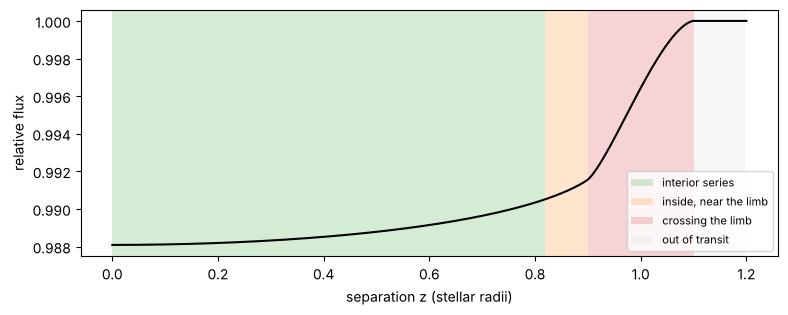

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(z, f, "k")
for lo, hi, col, name in [(0, z_c, "C2", "interior series"), (z_c, 1 - rp, "C1", "inside, near the limb"),
                          (1 - rp, 1 + rp, "C3", "crossing the limb"), (1 + rp, 1.2, "0.85", "out of transit")]:
    ax.axvspan(lo, hi, color=col, alpha=0.2, lw=0, label=name)
ax.set(xlabel="separation z (stellar radii)", ylabel="relative flux"); ax.legend(fontsize=8, loc="lower right");

In [4]:
for p in (0.0092, 0.05, 0.1, 0.2, 0.3):
    zc = series_cut(p, law, u)
    print(f"rp = {p:6.4f}: z_c / (1 - rp) = {zc / (1 - p):.3f}")

rp = 0.0092: z_c / (1 - rp) = 0.997
rp = 0.0500: z_c / (1 - rp) = 0.964
rp = 0.1000: z_c / (1 - rp) = 0.909
rp = 0.2000: z_c / (1 - rp) = 0.779
rp = 0.3000: z_c / (1 - rp) = 0.632


The interior series reaches closer to the limb for small planets: for an Earth-sized planet it covers all but
the last ~0.3 % of the distance to second contact.

## 3. The limb methods

| `limb=` | method | set-up | per limb sample | accuracy |
|---|---|---|---|---|
| `"fast"` (default) | `"interpolate"` for ≥ 150 limb samples, else `"trapezoid"` (rp < 0.3; larger: `"contact"` or quadrature) | — | — | ~1e-15 |
| `"trapezoid"` | fixed-node trapezoid rule for the limb integral written as a complete integral (paper Sect. 5.3) | none | 170–300 ns | ~1e-15 |
| `"interpolate"` | Chebyshev interpolants of that rule, through the connection formula at second contact | ~40 µs | 30–50 ns | ~1e-15 |
| `"contact"` | power series about first and second contact from Gauss hypergeometric functions (Sect. 5.2) | 0.1–1.7 ms | 50–80 ns | ~1e-15 |
| `"quadrature"` | Green's-theorem quadrature with a Gauss–Jacobi first segment | none | ~1 µs | ~1e-16 |
| `"proven"` | contact expansions split into pieces with a proven bound (Sect. 5.4) | 5–60 ms | 40–90 ns | ≤ `series_tol`, proven |

The reference is the quadrature with the series switched off (`series_tol=0`), itself verified against
40-digit arithmetic in the test suite.

In [5]:
zl = np.linspace(z_c + 1e-9, 1 + rp - 1e-9, 20000)          # limb samples only
ref = occult(zl, rp, u, law, series_tol=0.0, limb="quadrature")
print(f"{'limb=':14s} {'max |error|':>12s} {'ns per sample':>14s} {'one call, 2 samples [us]':>26s}")
for m in ("fast", "interpolate", "trapezoid", "contact", "quadrature", "proven"):
    err = np.max(np.abs(occult(zl, rp, u, law, limb=m) - ref))
    per = best(lambda: occult(zl, rp, u, law, limb=m)) / zl.size * 1e9
    small = best(lambda: occult(zl[:2], rp, u, law, limb=m)) * 1e6
    print(f"{m:14s} {err:12.1e} {per:14.0f} {small:26.0f}")

limb=           max |error|  ns per sample   one call, 2 samples [us]
fast                1.1e-16             34                         13
interpolate         1.1e-16             34                         47
trapezoid           1.1e-16            241                         13
contact             1.1e-16             60                         16


quadrature          0.0e+00           1043                         14


proven              4.3e-10            526                       9583


The last column is a call with only two limb samples: it shows the fixed set-up cost of each method, which
decides between them for short light curves. `"fast"` picks the cheapest accurate method automatically.

## 4. The error along the transit

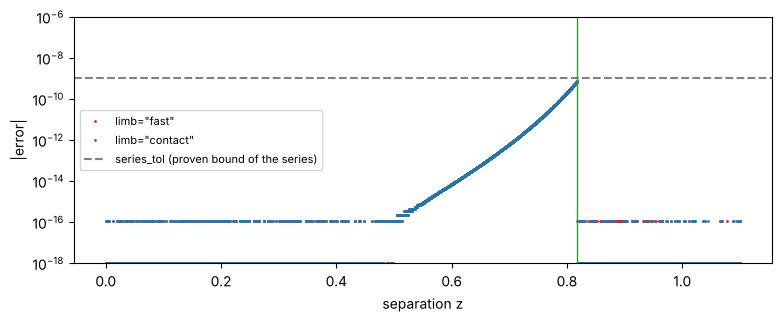

In [6]:
zz = np.concatenate([np.linspace(0, 1.1, 3000), 1 - rp + np.geomspace(1e-12, 0.1, 200) * np.array([1, -1]).repeat(100), 1 + rp - np.geomspace(1e-12, 0.1, 100)])
zz = np.sort(zz)
ref = occult(zz, rp, u, law, series_tol=0.0, limb="quadrature")
fig, ax = plt.subplots(figsize=(9, 3.2))
for m, col in (("fast", "C3"), ("contact", "C0")):
    e = np.abs(occult(zz, rp, u, law, limb=m) - ref)
    ax.semilogy(zz, np.maximum(e, 1e-18), ".", ms=2, color=col, label=f'limb="{m}"')
ax.axhline(1e-9, color="0.5", ls="--", label="series_tol (proven bound of the series)")
ax.axvline(z_c, color="C2", lw=1); ax.set(xlabel="separation z", ylabel="|error|", ylim=(1e-18, 1e-6)); ax.legend(fontsize=8);

Inside z_c the error is the series truncation, below the proven bound and in practice close to it; beyond z_c
the limb methods are at the level of rounding.

## What you learned

- `occult(z, rp, u, law, series_tol=, limb=)` is the engine behind `TransitModel`; `series_cut` gives the cut z_c.
- Inside z_c a polynomial with a proven error bound; at the limb a closed form (quadratic family) or one of several methods.
- `limb="fast"` chooses between the trapezoid rule and its interpolants; `"contact"`, `"quadrature"` and `"proven"` remain available.

**Next:** [08 · Error control and certification](08_error_control_and_certification.ipynb)